# Income classification on UCI Adult

**CO5177 · Tabular · CTG group**  
Huỳnh Thành Đạt (2570161) and Lương Minh Duy (2570083).

The task predicts annual income above USD 50,000 from 14 predictors. Four classifiers are compared: a majority baseline, two logistic regression variants, and histogram gradient boosting.

## 1. Environment

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import importlib.util

# In Colab, clone the repository if this notebook is outside a checkout.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
if not Path("configs/tabular.json").exists():
    checkout = Path("/content/CO5177-PFDAV")
    if not checkout.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/dathuynh1108/CO5177-PFDAV.git",
                str(checkout),
            ],
            check=True,
        )
    os.chdir(checkout)

REPO = Path.cwd().resolve()
required = ["numpy", "pandas", "sklearn", "pyarrow", "matplotlib"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", "requirements-studies.txt"],
        check=True,
    )
sys.path.insert(0, str(REPO / "src"))


In [2]:
import json
import time
from datetime import datetime
from datetime import timezone
from io import BytesIO

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from studies.evidence import metrics
from studies.tabular import NUMERIC
from studies.tabular import load
from studies.tabular import preprocessing


In [3]:
def show_figure(figure):
    """Display a PNG in Jupyter, including with a noninteractive backend."""
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=160, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))


### Run directory

In [4]:
with open(REPO / "configs/tabular.json", encoding="utf-8") as f:
    config = json.load(f)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUTPUT_ROOT = REPO / "artifacts" / "notebook-runs" / "tabular" / RUN_ID
OUTPUT_ROOT.mkdir(parents=True, exist_ok=False)
(OUTPUT_ROOT / "config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2) + "\n"
)
print(
    f"Run ID: {RUN_ID} | seed: {config['model_seed']} | split seed: {config['split_seed']}"
)
print(f"Run artifacts: {OUTPUT_ROOT}")


Run ID: 20261107T105935Z | seed: 42 | split seed: 2026
Run artifacts: /content/CO5177-PFDAV/artifacts/notebook-runs/tabular/20261107T105935Z


## 2. Data inspection

All 48,780 records remaining after duplicate and conflicting-label checks are used.

In [5]:
frame, data_audit = load(config)
print(
    f"Source: {data_audit['raw_rows']:,} rows; retained: {data_audit['retained_rows']:,}; "
    f"conflicting-label rows removed: {data_audit['conflicting_label_rows_removed']:,}; "
    f"duplicate rows removed: {data_audit['duplicate_rows_removed_after_conflicts']:,}"
)
display(pd.DataFrame({"missing": data_audit["missing_by_column"]}))


Source: 48,842 rows; retained: 48,780; conflicting-label rows removed: 10; duplicate rows removed: 52


,missing
age,0
fnlwgt,0
education_num,0
capital_gain,0
capital_loss,0
hours_per_week,0
workclass,2799
education,0
marital_status,0
occupation,2809


### Class balance and missing values

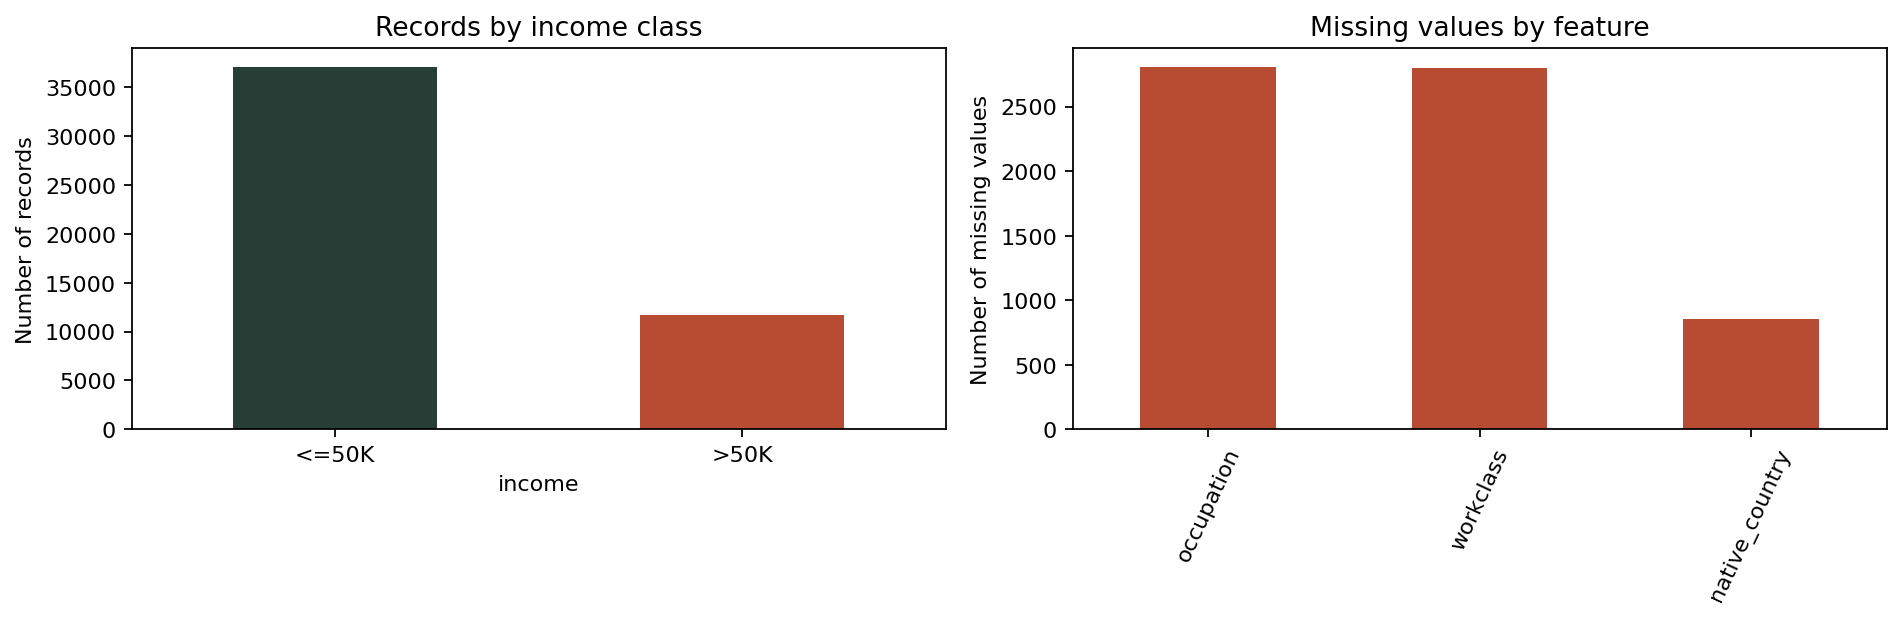

624

In [6]:
class_counts = frame["income"].value_counts().reindex(["<=50K", ">50K"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.plot.bar(ax=axes[0], color=["#263e35", "#b74c32"], rot=0)
axes[0].set(title="Records by income class", ylabel="Number of records")
missing = pd.Series(data_audit["missing_by_column"]).sort_values(ascending=False)
missing[missing > 0].plot.bar(ax=axes[1], color="#b74c32", rot=65)
axes[1].set(title="Missing values by feature", ylabel="Number of missing values")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "eda.png", dpi=160)
show_figure(fig)
plt.close(fig)
data_audit["class_counts"] = {str(k): int(v) for k, v in class_counts.items()}
(OUTPUT_ROOT / "data_audit.json").write_text(
    json.dumps(data_audit, ensure_ascii=False, indent=2) + "\n"
)


## 3. Data partitions

Stratified train/validation/test split: 70/15/15, using seeds 2026 and 2027.

In [7]:
target = (frame["income"] == ">50K").astype(int).to_numpy()
train_idx, remainder_idx = train_test_split(
    np.arange(len(frame)),
    test_size=0.30,
    random_state=config["split_seed"],
    stratify=target,
)
validation_idx, test_idx = train_test_split(
    remainder_idx,
    test_size=0.5,
    random_state=config["split_seed"] + 1,
    stratify=target[remainder_idx],
)
print("Train / validation / test:", len(train_idx), len(validation_idx), len(test_idx))


(OUTPUT_ROOT / "splits.json").write_text(
    json.dumps(
        {
            "train_ids": frame.iloc[train_idx]["id"].tolist(),
            "validation_ids": frame.iloc[validation_idx]["id"].tolist(),
            "test_ids": frame.iloc[test_idx]["id"].tolist(),
        },
        ensure_ascii=False,
    )
    + "\n"
)


Train / validation / test: 34146 7317 7317


1434156

## 4. Numerical training features

Summaries and histograms use training records only.

In [8]:
training_numeric = frame.iloc[train_idx][NUMERIC]
numeric_summary = training_numeric.describe().T
print("Numerical summary of the training set:")
display(numeric_summary.round(2))
numeric_summary.to_csv(
    OUTPUT_ROOT / "training_numeric_summary.csv", index_label="Feature"
)


Numerical summary of the training set:


,count,mean,std,min,25%,50%,75%,max
age,34146.0,38.62,13.67,17.0,28.0,37.0,48.0,90.0
fnlwgt,34146.0,189063.57,105144.10,13769.0,117381.0,177907.0,236731.0,1484705.0
education_num,34146.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital_gain,34146.0,1055.67,7309.55,0.0,0.0,0.0,0.0,99999.0
capital_loss,34146.0,88.68,405.24,0.0,0.0,0.0,0.0,4356.0
hours_per_week,34146.0,40.45,12.35,1.0,40.0,40.0,45.0,99.0


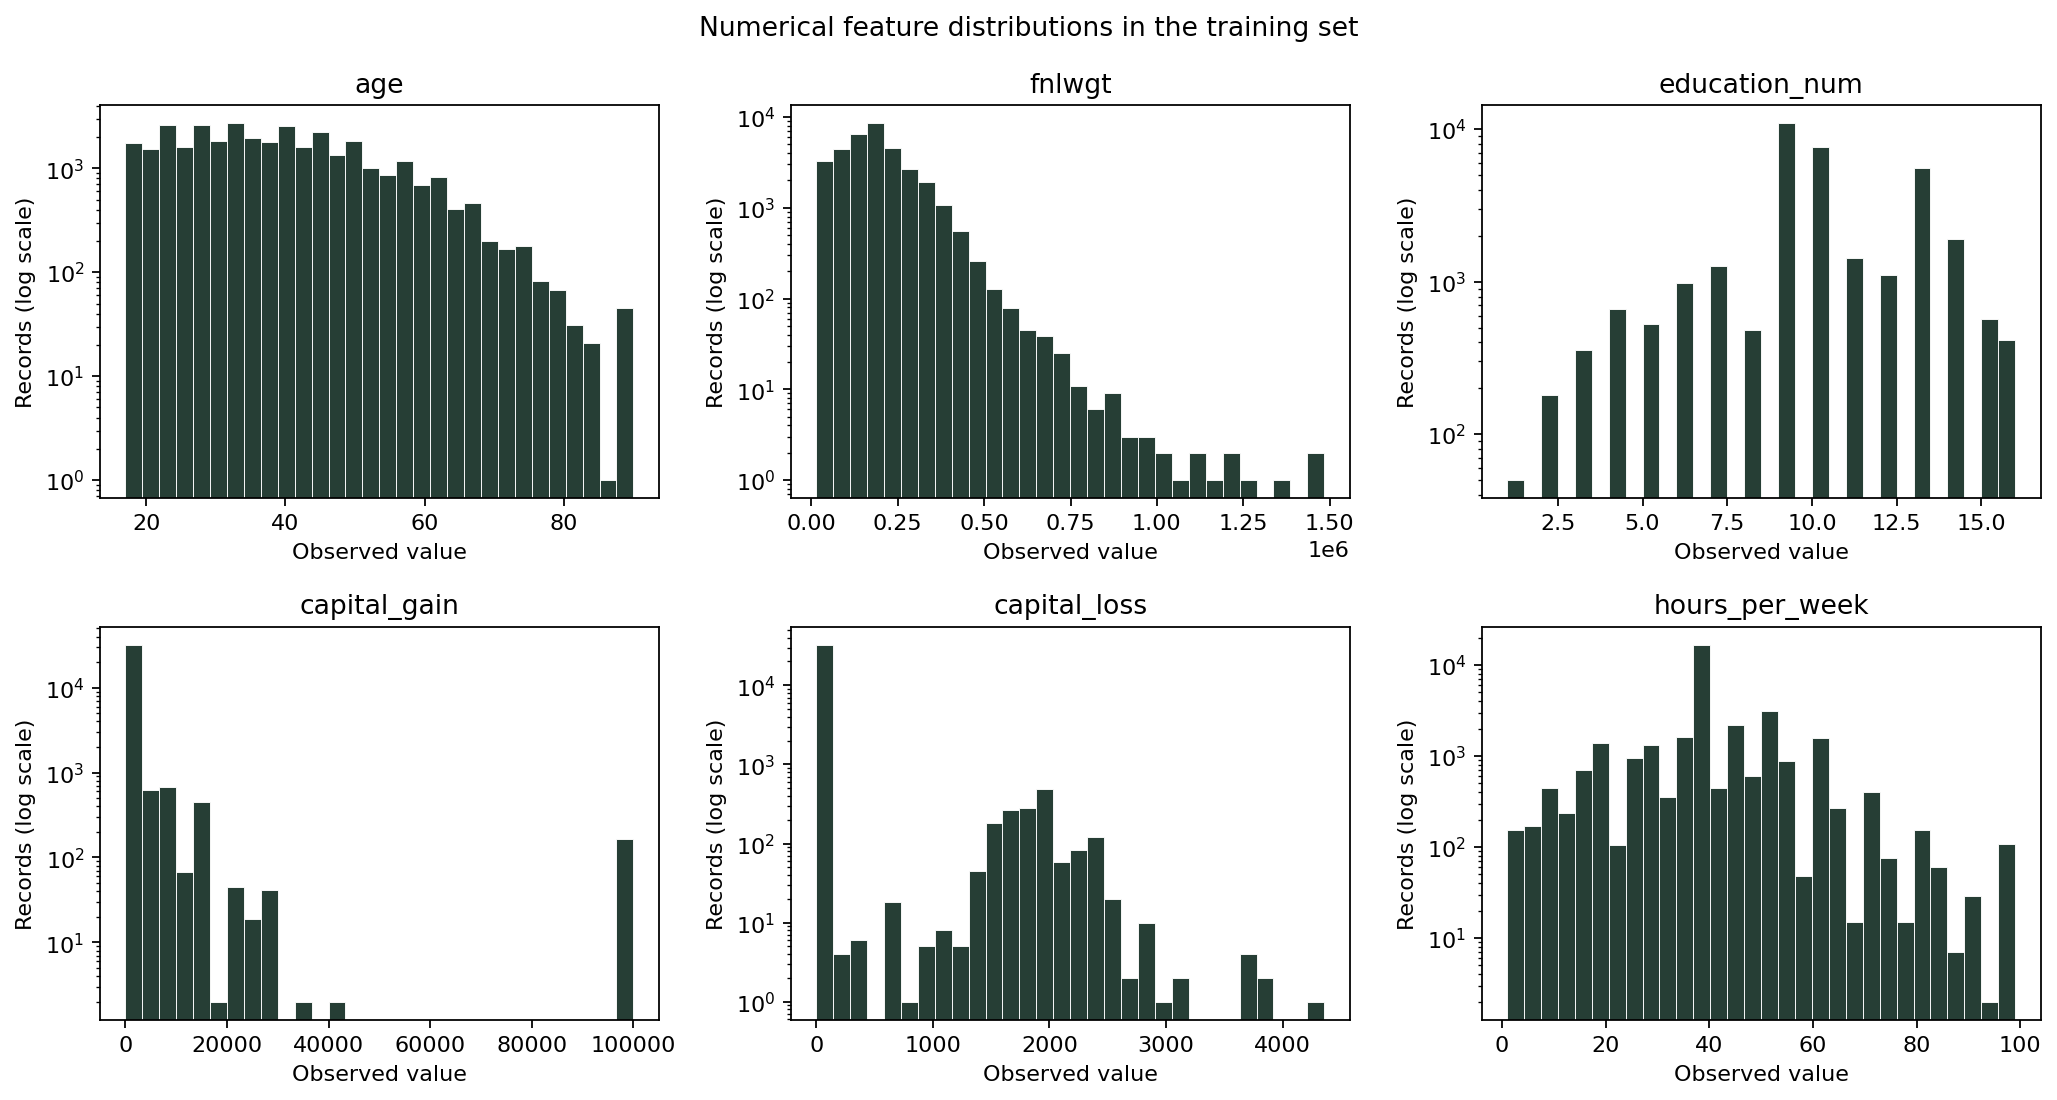

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for feature, ax in zip(NUMERIC, axes.flat):
    ax.hist(
        training_numeric[feature].dropna(),
        bins=30,
        color="#263e35",
        edgecolor="white",
        linewidth=0.4,
    )
    ax.set(
        title=feature,
        xlabel="Observed value",
        ylabel="Records (log scale)",
        yscale="log",
    )
fig.suptitle("Numerical feature distributions in the training set")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "training_numeric_distributions.png", dpi=160)
show_figure(fig)
plt.close(fig)


### Extreme values

In [10]:
q1 = training_numeric.quantile(0.25)
q3 = training_numeric.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
extreme_counts = (training_numeric.lt(lower) | training_numeric.gt(upper)).sum()
iqr_summary = pd.DataFrame(
    {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower fence": lower,
        "Upper fence": upper,
        "Flagged records": extreme_counts,
        "Flagged (%)": extreme_counts / len(training_numeric) * 100,
    }
)
iqr_summary.index.name = "Feature"
print("Training-only IQR flags; flagged values are retained:")
display(iqr_summary.round(2))
iqr_summary.to_csv(OUTPUT_ROOT / "training_iqr_flags.csv")


Training-only IQR flags; flagged values are retained:


,Q1,Q3,IQR,Lower fence,Upper fence,Flagged records,Flagged (%)
Feature,,,,,,,
age,28.0,48.0,20.0,-2.0,78.0,146,0.43
fnlwgt,117381.0,236731.0,119350.0,-61644.0,415756.0,1012,2.96
education_num,9.0,12.0,3.0,4.5,16.5,1257,3.68
capital_gain,0.0,0.0,0.0,0.0,0.0,2772,8.12
capital_loss,0.0,0.0,0.0,0.0,0.0,1618,4.74
hours_per_week,40.0,45.0,5.0,32.5,52.5,9461,27.71


Capital gains and losses have zero IQR; positive values are flagged but retained because these flags do not establish recording errors.

## 5. Model comparison

In [11]:
candidates = [
    ("Majority baseline", None, [None]),
    ("Logistic regression", "logistic", config["logistic_c"]),
    ("Balanced logistic regression", "balanced", config["logistic_c"]),
    ("Histogram gradient boosting", "histogram", [None]),
]
labels = ["<=50K", ">50K"]


### Candidate fitting

Imputation, scaling, encoding, and classifiers are fitted on training data only.

In [12]:
fitted_candidates = []
for name, kind, c_values in candidates:
    for c in c_values:
        if kind is None:
            classifier = DummyClassifier(strategy="most_frequent")
        elif kind == "histogram":
            classifier = HistGradientBoostingClassifier(
                max_iter=150,
                max_leaf_nodes=31,
                l2_regularization=1.0,
                early_stopping=False,
                categorical_features=list(range(6, 14)),
                random_state=config["model_seed"],
            )
        else:
            classifier = LogisticRegression(
                C=c,
                max_iter=2000,
                class_weight="balanced" if kind == "balanced" else None,
                random_state=config["model_seed"],
            )
        model = Pipeline(
            [
                ("preprocess", preprocessing(tree=kind == "histogram")),
                ("classifier", classifier),
            ]
        )
        started = time.perf_counter()
        model.fit(frame.iloc[train_idx], target[train_idx])
        elapsed = time.perf_counter() - started
        fitted_candidates.append(
            {
                "name": name,
                "C": c,
                "model": model,
                "fit_seconds": elapsed,
            }
        )
        print(f"{name}, C={c}: fitted in {elapsed:.2f}s")


Majority baseline, C=None: fitted in 0.29s
Logistic regression, C=0.1: fitted in 0.63s
Logistic regression, C=1.0: fitted in 0.57s
Logistic regression, C=10.0: fitted in 0.56s
Balanced logistic regression, C=0.1: fitted in 0.50s
Balanced logistic regression, C=1.0: fitted in 0.59s
Balanced logistic regression, C=10.0: fitted in 0.64s
Histogram gradient boosting, C=None: fitted in 1.33s


### Validation selection

Selection uses validation macro-F1 before test predictions.

In [13]:
models = {}
records = []
fit_history = []
for name, kind, c_values in candidates:
    best_score = -1.0
    best_model = None
    best_c = None
    trials = []
    for candidate in fitted_candidates:
        if candidate["name"] != name:
            continue
        model = candidate["model"]
        c = candidate["C"]
        prediction = model.predict(frame.iloc[validation_idx])
        score = metrics(target[validation_idx], prediction, labels)
        trial = {
            "C": c,
            "validation_accuracy": score["accuracy"],
            "validation_macro_f1": score["macro_f1"],
            "fit_seconds": candidate["fit_seconds"],
        }
        trials.append(trial)
        fit_history.append({"model": name, **trial})
        print(f"{name}, C={c}: validation macro-F1={score['macro_f1']:.4f}")
        if score["macro_f1"] > best_score:
            best_score = score["macro_f1"]
            best_model = model
            best_c = c
    models[name] = best_model
    records.append(
        {
            "name": name,
            "selected_C": best_c,
            "validation_trials": trials,
            "validation_macro_f1": best_score,
        }
    )

(OUTPUT_ROOT / "fit_history.json").write_text(
    json.dumps(fit_history, ensure_ascii=False, indent=2) + "\n"
)
validation_table = pd.DataFrame(
    [
        {
            "Model": record["name"],
            "Selected C": record["selected_C"],
            "Validation macro-F1": record["validation_macro_f1"],
        }
        for record in records
    ]
)
display(validation_table.set_index("Model").round(4))


Majority baseline, C=None: validation macro-F1=0.4320
Logistic regression, C=0.1: validation macro-F1=0.7796
Logistic regression, C=1.0: validation macro-F1=0.7798
Logistic regression, C=10.0: validation macro-F1=0.7803
Balanced logistic regression, C=0.1: validation macro-F1=0.7634
Balanced logistic regression, C=1.0: validation macro-F1=0.7637
Balanced logistic regression, C=10.0: validation macro-F1=0.7639
Histogram gradient boosting, C=None: validation macro-F1=0.8147


,Selected C,Validation macro-F1
Model,,
Majority baseline,NaN,0.4320
Logistic regression,10.0,0.7803
Balanced logistic regression,10.0,0.7639
Histogram gradient boosting,NaN,0.8147


## 6. Held-out test evaluation

In [14]:
test_target = target[test_idx]
predictions = pd.DataFrame(
    {"id": frame.iloc[test_idx]["id"].to_numpy(), "target": test_target}
)
for record in records:
    name = record["name"]
    predicted = models[name].predict(frame.iloc[test_idx])
    measured = metrics(test_target, predicted, labels)
    record["test"] = measured
    predictions[name] = predicted
    joblib.dump(
        models[name],
        OUTPUT_ROOT / (name.lower().replace(" ", "_") + ".joblib"),
        compress=3,
    )
predictions.to_csv(OUTPUT_ROOT / "predictions.csv", index=False)
summary = {
    "track": "tabular",
    "run_id": RUN_ID,
    "seed": config["model_seed"],
    "split_seed": config["split_seed"],
    "split_sizes": {
        "train": len(train_idx),
        "validation": len(validation_idx),
        "test": len(test_idx),
    },
    "classes": labels,
    "models": records,
}
(OUTPUT_ROOT / "metrics.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2) + "\n"
)


6822

### Test metrics

In [15]:
rows = []
for result in records:
    minority = result["test"]["per_class"][">50K"]
    rows.append(
        {
            "Model": result["name"],
            "C": result["selected_C"],
            "Validation macro-F1": result["validation_macro_f1"],
            "Test accuracy": result["test"]["accuracy"],
            "Test macro-F1": result["test"]["macro_f1"],
            "Precision >50K": minority["precision"],
            "Recall >50K": minority["recall"],
        }
    )
display(pd.DataFrame(rows).set_index("Model").round(4))


,C,Validation macro-F1,Test accuracy,Test macro-F1,Precision >50K,Recall >50K
Model,,,,,,
Majority baseline,NaN,0.4320,0.7606,0.4320,0.0000,0.0000
Logistic regression,10.0,0.7803,0.8524,0.7815,0.7403,0.5908
Balanced logistic regression,10.0,0.7639,0.8143,0.7769,0.5764,0.8459
Histogram gradient boosting,NaN,0.8147,0.8748,0.8185,0.7805,0.6638


### Scores and confusion matrix

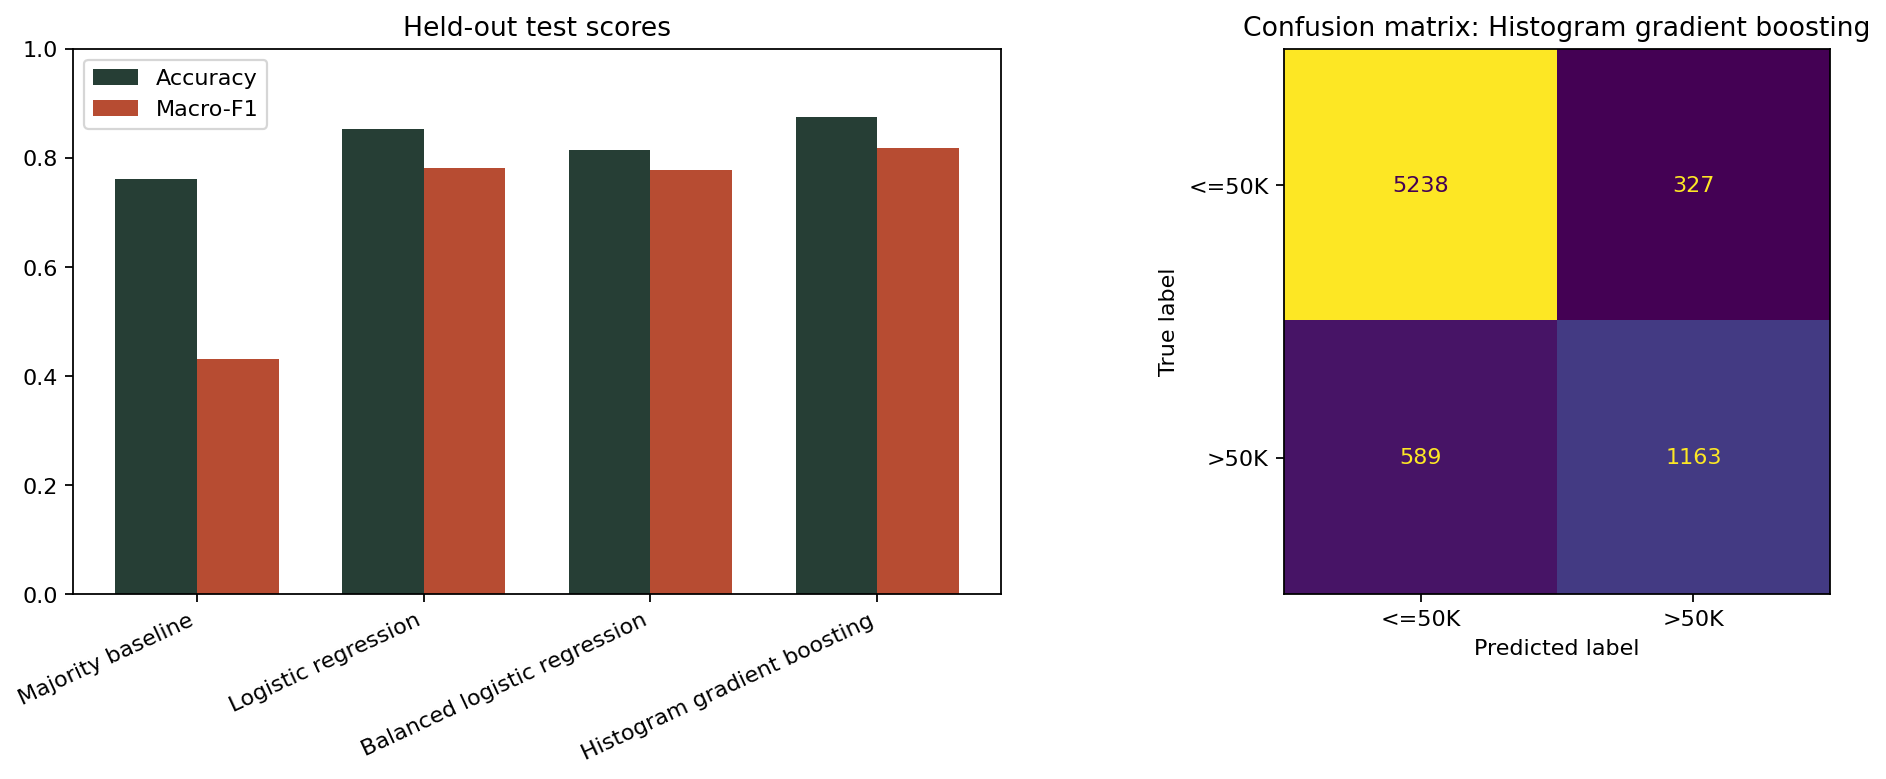

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
names = [r["name"] for r in records]
x = np.arange(len(names))
axes[0].bar(
    x - 0.18,
    [r["test"]["accuracy"] for r in records],
    0.36,
    label="Accuracy",
    color="#263e35",
)
axes[0].bar(
    x + 0.18,
    [r["test"]["macro_f1"] for r in records],
    0.36,
    label="Macro-F1",
    color="#b74c32",
)
axes[0].set_xticks(x, names, rotation=25, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_title("Held-out test scores")
axes[0].legend()
selected = max(records, key=lambda r: r["validation_macro_f1"])
ConfusionMatrixDisplay(
    np.asarray(selected["test"]["confusion"]), display_labels=labels
).plot(ax=axes[1], colorbar=False, values_format="d")
axes[1].set_title("Confusion matrix: " + selected["name"])
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "test_metrics_confusion.png", dpi=160)
show_figure(fig)
plt.close(fig)


In [17]:
for result in records:
    minority = result["test"]["per_class"][">50K"]
    print(
        f"{result['name']}: precision >50K={minority['precision']:.4f}; recall >50K={minority['recall']:.4f}"
    )
print(
    "Predictions, fitted models, configuration, fit history, metrics, and figures saved to",
    OUTPUT_ROOT,
)


Majority baseline: precision >50K=0.0000; recall >50K=0.0000
Logistic regression: precision >50K=0.7403; recall >50K=0.5908
Balanced logistic regression: precision >50K=0.5764; recall >50K=0.8459
Histogram gradient boosting: precision >50K=0.7805; recall >50K=0.6638
Predictions, fitted models, configuration, fit history, metrics, and figures saved to /content/CO5177-PFDAV/artifacts/notebook-runs/tabular/20261107T105935Z


## 7. Findings and limitations

Histogram gradient boosting reaches 87.48% test accuracy and 0.8185 macro-F1. Class weighting raises logistic regression recall for >50K from 59.08% to 84.59%, while precision falls from 74.03% to 57.64%.

Results cover one split and model seed. Adult reflects 1994 Census data.

## 8. AI assistance disclosure

AI assistance is documented in [AI_USE_REPORT.md](https://github.com/dathuynh1108/CO5177-PFDAV/blob/main/AI_USE_REPORT.md).